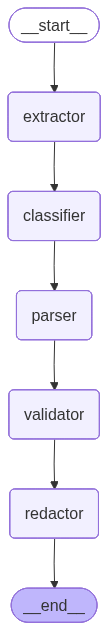

In [3]:
## import dependencies
from src.state_schema import DocumentState
from langgraph.graph import StateGraph, START, END

## import agents
from src.extractor_agent import extractor
from src.classifier_agent import classifier
from src.parser_agent import parser
from src.validator_agent import validator
from src.redactor_agent import redactor

## define the Graph
graph = StateGraph(state_schema=DocumentState)

## add nodes
graph.add_node("extractor", extractor)
graph.add_node("classifier", classifier)
graph.add_node("parser", parser)
graph.add_node("validator", validator)
graph.add_node("redactor", redactor)

## add edges
graph.add_edge(START, "extractor")
graph.add_edge("extractor", "classifier")
graph.add_edge("classifier", "parser")
graph.add_edge("parser", "validator")
graph.add_edge("validator", "redactor")
graph.add_edge("redactor", END)

## compile
workflow = graph.compile()

workflow